# CS412 — Machine Learning
Recitation 3 · Linear Regression

---
<a id='section1'></a>

# 1 · What is Linear Regression?

Linear regression models the relationship between an **input** (or set of inputs) and a **continuous output** by fitting a straight line — or, in multiple dimensions, a hyperplane.

### The simplest case — one feature

$$\boxed{\hat{y} = w x + b}$$

| Symbol | Name | Meaning |
|--------|------|---------|
| $x$ | Feature | The input value |
| $\hat{y}$ | Prediction | Our model's output |
| $w$ | Weight (slope) | How much $y$ changes per unit of $x$ |
| $b$ | Bias (intercept) | The value of $\hat{y}$ when $x = 0$ |

### Why do we care?

Linear regression answers three practical questions:

1. **Prediction** — Given new $x$ values, what will $y$ be?
2. **Feature importance** — Which inputs matter most, and in which direction?
3. **Trend estimation** — What is the underlying trend in a time series?

> **Key insight:** The model *learns* $w$ and $b$ from data by minimising the total prediction error.

---
<a id='section2'></a>

# 2 · The Matrix Formulation — Theory

## 2.1 — Setting up the system

Suppose we have $N$ training points $\{(x_i, y_i)\}_{i=1}^{N}$. Writing the linear model for every point simultaneously gives a **system of linear equations**:

$$
\begin{cases}
y_1 = b + w \cdot x_1 \\
y_2 = b + w \cdot x_2 \\
\;\vdots \\
y_N = b + w \cdot x_N
\end{cases}
$$

We stack these into matrix form. We pack the *bias column* (all ones) together with the feature column into a **design matrix** $X$:

$$
\underbrace{\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_N \end{bmatrix}}_{\mathbf{y}}
=
\underbrace{\begin{bmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_N \end{bmatrix}}_{X \;(N \times 2)}
\underbrace{\begin{bmatrix} b \\ w \end{bmatrix}}_{\boldsymbol{\beta}}
$$


---
<a id='section3'></a>

# 3 · Worked Example — Slides Walkthrough

This section reproduces and extends the four cases shown in the lecture slides, step by step with full matrix arithmetic so you can present each case confidently.

---

## Case 1 — Two Points, No Noise (Square, Exact Inverse)

**Given:**  $(x_1, y_1) = (1, 5)$ and $(x_2, y_2) = (2, 7)$.  
Underlying truth: $f(x) = 2x + 3$.

### Step 1 — Write the design matrix

$$
X = \begin{bmatrix} 1 & 1 \\ 1 & 2 \end{bmatrix}
\qquad
\mathbf{y} = \begin{bmatrix} 5 \\ 7 \end{bmatrix}
$$

### Step 2 — Compute the inverse (square system)

For a $2\times 2$ matrix $\begin{bmatrix}a&b\\c&d\end{bmatrix}$, the inverse is $\frac{1}{det(x)}\begin{bmatrix}d&-b\\-c&a\end{bmatrix}$.

$$
\det(X) = ad-bc = 1\cdot2 - 1\cdot1 = 1
\qquad
X^{-1} = \frac{1}{1}\begin{bmatrix} 2 & -1 \\ -1 & 1 \end{bmatrix} = \begin{bmatrix} 2 & -1 \\ -1 & 1 \end{bmatrix}
$$

### Step 3 — Recover the parameters

$$
\boldsymbol{\hat{\beta}} = X^{-1}\mathbf{y} =
\begin{bmatrix} 2 & -1 \\ -1 & 1 \end{bmatrix}
\begin{bmatrix} 5 \\ 7 \end{bmatrix}
=
\begin{bmatrix} 2(5) + (-1)(7) \\ (-1)(5) + 1(7) \end{bmatrix}
=
\begin{bmatrix} 3 \\ 2 \end{bmatrix}
$$

$$\Rightarrow\quad b = 3, \quad w = 2 \quad\Longrightarrow\quad \hat{f}(x) = 2x + 3 \checkmark$$

> **We recover the exact parameters** — because we have exactly as many points as unknowns and there is no noise.

---

## Case 2 — Two Points, With Noise (Still Exact Fit, But Wrong Parameters)

**Given:** same $X$, but now $\mathbf{y} = \begin{bmatrix}5.1 \\ 6.9\end{bmatrix}$ (noisy observations of the same truth).

$$
\boldsymbol{\hat{\beta}} = X^{-1}\mathbf{y} =
\begin{bmatrix} 2 & -1 \\ -1 & 1 \end{bmatrix}
\begin{bmatrix} 5.1 \\ 6.9 \end{bmatrix}
=
\begin{bmatrix} 2(5.1) - 6.9 \\ -5.1 + 6.9 \end{bmatrix}
=
\begin{bmatrix} 3.3 \\ 1.8 \end{bmatrix}
$$

> **Residual = 0, but the recovered parameters are wrong!**  
> With only 2 points and 2 unknowns, a line can always pass through them exactly — we just *overfit* to the noise.  
> The real $b=3, w=2$ are not recovered.

---

## Case 3 — Three Points, No Noise (Rectangular, Pseudoinverse)

**Given:** $(x_1,y_1)=(1,5)$, $(x_2,y_2)=(2,7)$, $(x_3,y_3)=(4,11)$.  
Underlying truth: $f(x)=2x+3$.

### Step 1 — Design matrix (now rectangular, $3\times2$)

$$
X = \begin{bmatrix} 1 & 1 \\ 1 & 2 \\ 1 & 4 \end{bmatrix}
\qquad
\mathbf{y} = \begin{bmatrix} 5 \\ 7 \\ 11 \end{bmatrix}
$$

> `np.linalg.inv(X)` → **Error: Matrix must be square.**  
> We need the **pseudoinverse** instead.

### Step 2 — Compute $X^+ = (X^T X)^{-1} X^T$

From NumPy (`np.linalg.pinv(X)`):

$$
X^+ \approx
\begin{bmatrix}
 1.0000 & \phantom{-}0.5000 & -0.5000 \\
-0.2857 & -0.0714 & \phantom{-}0.3571
\end{bmatrix}
$$

### Step 3 — Solve

$$
\boldsymbol{\hat{\beta}} = X^+\mathbf{y} =
\begin{bmatrix} 1.0(5)+0.5(7)+(-0.5)(11) \\ -0.2857(5)+(-0.0714)(7)+0.3571(11) \end{bmatrix}
= \begin{bmatrix} 3.0 \\ 2.0 \end{bmatrix}
$$

$$\Rightarrow\quad b=3, \quad w=2 \quad\Longrightarrow\quad \hat{f}(x) = 2x+3 \checkmark$$

> **Exact parameters recovered again** — more data (no noise) makes the system more constrained, so the pseudoinverse finds the true answer.

---

## Case 4 — Three Points, With Noise (Least-Squares Approximate Fit)

**Given:** same $X$, but $\mathbf{y} = \begin{bmatrix}5 \\ 7 \\ 11.5\end{bmatrix}$ (third point is noisy).

$$
\boldsymbol{\hat{\beta}} = X^+\mathbf{y} = \begin{bmatrix} 2.7500 \\ 2.1786 \end{bmatrix}
\qquad\Rightarrow\quad \hat{f}(x) = 2.1786x + 2.75
$$

### Predictions vs. actuals:

$$
\hat{\mathbf{y}} = X\boldsymbol{\hat{\beta}} =
\begin{bmatrix} 4.9286 \\ 7.1071 \\ 11.4643 \end{bmatrix}
\neq
\begin{bmatrix} 5 \\ 7 \\ 11.5 \end{bmatrix}
$$

### Residual sum of squares:

$$
\sum_{i=1}^{3}(y_i - \hat{y}_i)^2
= (5 - 4.9286)^2 + (7 - 7.1071)^2 + (11.5 - 11.4643)^2
\approx 0.01786
$$

> **The pseudoinverse minimises this residual** — it gives the best possible fit under the least-squares criterion.  
> The residual is non-zero but as small as it can be.

# Python Examples

---
<a id='section4'></a>

# 4 · Generating & Visualising Synthetic Data

We now create a dataset that mimics a real-world scenario: data generated by a known linear law **plus random noise**.

The underlying (true) function is:

$$\boxed{y = 5x + 20 + \epsilon, \qquad \epsilon \sim \mathcal{N}(0,\sigma^2)}$$

Our goal is to *recover* $w=5$ and $b=20$ from noisy observations.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ── Parameters ───────────────────────────────────────────────────────────────
np.random.seed(42)          # reproducibility
sample_size  = 15
TRUE_SLOPE   = 5
TRUE_BIAS    = 20
NOISE_STDDEV = 8            # standard deviation of noise

# ── Generate data ────────────────────────────────────────────────────────────
x = np.arange(sample_size)
y_clean = x * TRUE_SLOPE + TRUE_BIAS
noise   = np.random.randn(sample_size) * NOISE_STDDEV
y       = y_clean + noise

print("x values:", x)
print("y values (without noise):", np.round(y_clean, 2))
print("y values (with noise):", np.round(y, 2))

x values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
y values (without noise): [20 25 30 35 40 45 50 55 60 65 70 75 80 85 90]
y values (with noise): [23.97 23.89 35.18 47.18 38.13 43.13 62.63 61.14 56.24 69.34 66.29 71.27
 81.94 69.69 76.2 ]


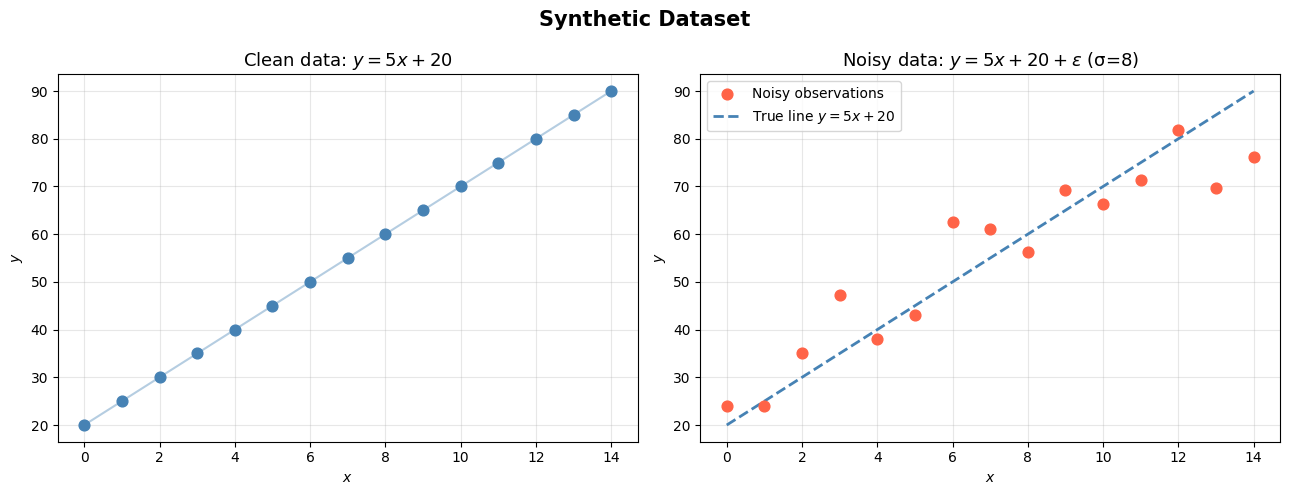

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: clean data
axes[0].scatter(x, y_clean, color='steelblue', s=60, zorder=5)
axes[0].plot(x, y_clean, color='steelblue', alpha=0.4)
axes[0].set_title('Clean data: $y = 5x + 20$', fontsize=13)
axes[0].set_xlabel('$x$'); axes[0].set_ylabel('$y$')
axes[0].grid(True, alpha=0.3)

# Right: noisy data
axes[1].scatter(x, y, color='tomato', s=60, zorder=5, label='Noisy observations')
axes[1].plot(x, y_clean, color='steelblue', linewidth=2, linestyle='--', label='True line $y=5x+20$')
axes[1].set_title(f'Noisy data: $y = 5x + 20 + \\epsilon$ (σ={NOISE_STDDEV})', fontsize=13)
axes[1].set_xlabel('$x$'); axes[1].set_ylabel('$y$')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Synthetic Dataset', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='section5'></a>

# 5 · Fitting with scikit-learn

scikit-learn's `LinearRegression` is the standard, battle-tested way to fit linear models in Python. Internally it also uses the pseudoinverse / least-squares solver.

---

## 5.1 · Why scikit-learn Expects a 2-D Matrix

scikit-learn is designed to handle **any number of features** — not just one. So it always expects your input `X` to be a 2-D array of shape `(n_samples, n_features)`, where:

- **rows** = individual data points (samples)
- **columns** = input variables (features)

This generalises naturally. With one feature (house size) you have shape `(N, 1)`. With two features (house size + bedrooms) you have shape `(N, 2)`, and so on:

$$
X_{\text{1 feature}} =
\begin{bmatrix}
x_1 \\ x_2 \\ \vdots \\ x_N
\end{bmatrix}
\xrightarrow{\text{reshape}}
\begin{bmatrix}
x_1 \\ x_2 \\ \vdots \\ x_N
\end{bmatrix}_{N \times 1}
\qquad
X_{\text{2 features}} =
\begin{bmatrix}
x_1^{(1)} & x_1^{(2)} \\
x_2^{(1)} & x_2^{(2)} \\
\vdots & \vdots \\
x_N^{(1)} & x_N^{(2)}
\end{bmatrix}_{N \times 2}
$$

Because the interface is the same whether you have 1 or 100 features, scikit-learn enforces 2-D input **always** — even in the single-feature case.

---

## 5.2 · The Reshape Fix

Our `x` array comes out of NumPy as 1-D — a flat list of numbers with shape `(15,)`. scikit-learn will reject this with an error. We fix it with `.reshape(-1, 1)`:

In [ ]:
from sklearn.linear_model import LinearRegression

# ── Step 1: Reshape ───────────────────────────────────────────────────────────
X_sk = x.reshape(-1, 1)   # shape (15, 1) — one feature per sample

# ── Step 2: Fit ───────────────────────────────────────────────────────────────
model = LinearRegression()
model.fit(X_sk, y)   # y_pred_manual = w_hat * x + b_hat

# ── Step 3: Inspect learned parameters ───────────────────────────────────────
w_hat = model.coef_[0]
b_hat = model.intercept_

print(f"True parameters:     w = {TRUE_SLOPE},   b = {TRUE_BIAS}")
print(f"Learned parameters:  w = {w_hat:.4f},  b = {b_hat:.4f}")
print(f"\nFitted line: ŷ = {w_hat:.4f}·x + {b_hat:.4f}")

True parameters:     w = 5,   b = 20
Learned parameters:  w = 3.9323,  b = 27.5564

Fitted line: ŷ = 3.9323·x + 27.5564


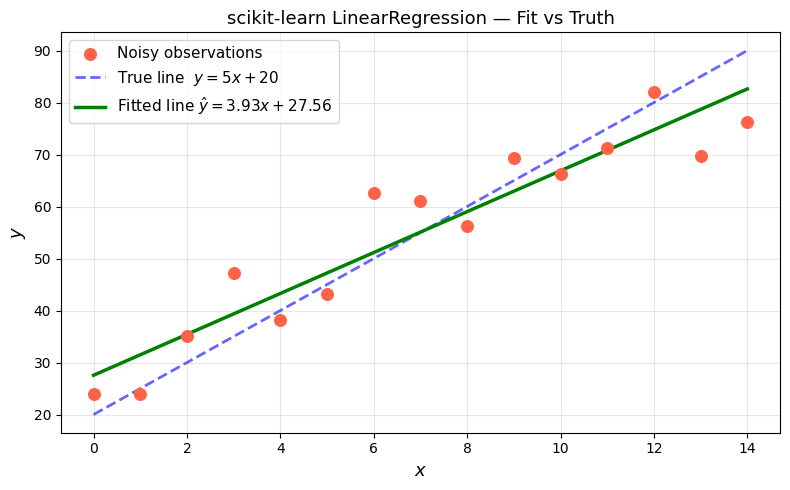

Max difference between manual and sklearn predict: 0.0


In [ ]:
# ── Predict & Plot ────────────────────────────────────────────────────────────
y_pred = model.predict(X_sk)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color='tomato', s=70, zorder=5, label='Noisy observations')
ax.plot(x, y_clean, 'b--', linewidth=2, alpha=0.6, label='True line  $y = 5x+20$')
ax.plot(x, y_pred,  'g-',  linewidth=2.5,          label=f'Fitted line $\\hat{{y}} = {w_hat:.2f}x + {b_hat:.2f}$')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('scikit-learn LinearRegression — Fit vs Truth', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── Verify that manual and sklearn predictions are identical ──────────────────
y_pred_manual = w_hat * x + b_hat
print("Max difference between manual and sklearn predict:", np.max(np.abs(y_pred_manual - y_pred)))

---
<a id='section6'></a>

# 6 · Fitting with the Pseudoinverse (NumPy)

Here we reproduce the exact same least-squares solution as scikit-learn, but manually — so you can see every step.

**Procedure:**

1. Build the design matrix $X$ of shape $(N, 2)$ — column of ones + feature column
2. Compute $X^+ = \texttt{np.linalg.pinv}(X)$
3. Multiply: $\boldsymbol{\hat{\beta}} = X^+ \mathbf{y}$

In [ ]:
from sympy import Matrix
from IPython.display import display

# ── Build design matrix X ─────────────────────────────────────────────────────
X_np = np.column_stack([np.ones(sample_size), x])   # shape (15, 2)

print("Design matrix X  (first column = 1s for bias, second = features) [shape 15 × 2]:")
display(Matrix(X_np).applyfunc(lambda v: int(v)))

Design matrix X  (first column = 1s for bias, second = features) [shape 15 × 2]:


Matrix([
[1,  0],
[1,  1],
[1,  2],
[1,  3],
[1,  4],
[1,  5],
[1,  6],
[1,  7],
[1,  8],
[1,  9],
[1, 10],
[1, 11],
[1, 12],
[1, 13],
[1, 14]])

In [ ]:
# ── Compute pseudoinverse ─────────────────────────────────────────────────────
X_pinv = np.linalg.pinv(X_np)   # shape (2, 15)

print("Pseudoinverse X⁺  = (XᵀX)⁻¹Xᵀ   [shape 2 × 15]:")
display(Matrix(X_pinv).applyfunc(lambda v: round(v, 3)))

Pseudoinverse X⁺  = (XᵀX)⁻¹Xᵀ   [shape 2 × 15]:


Matrix([
[ 0.242,  0.217,  0.192,  0.167,  0.142,  0.117,  0.092, 0.067, 0.042, 0.017, -0.008, -0.033, -0.058, -0.083, -0.108],
[-0.025, -0.021, -0.018, -0.014, -0.011, -0.007, -0.004,   0.0, 0.004, 0.007,  0.011,  0.014,  0.018,  0.021,  0.025]])

In [ ]:
# ── Solve for β̂ ──────────────────────────────────────────────────────────────
beta_np = X_pinv @ y
b_np, w_np = beta_np

print(f"β̂ = X⁺·y  →  b = {b_np:.4f},  w = {w_np:.4f}")

# Confirm it matches sklearn exactly
print(f"\nsklearn   →  b = {b_hat:.4f},  w = {w_hat:.4f}")

β̂ = X⁺·y  →  b = 27.5564,  w = 3.9323

sklearn   →  b = 27.5564,  w = 3.9323
Difference: Δb = 3.55e-15,  Δw = 2.22e-15   (numerical noise only)


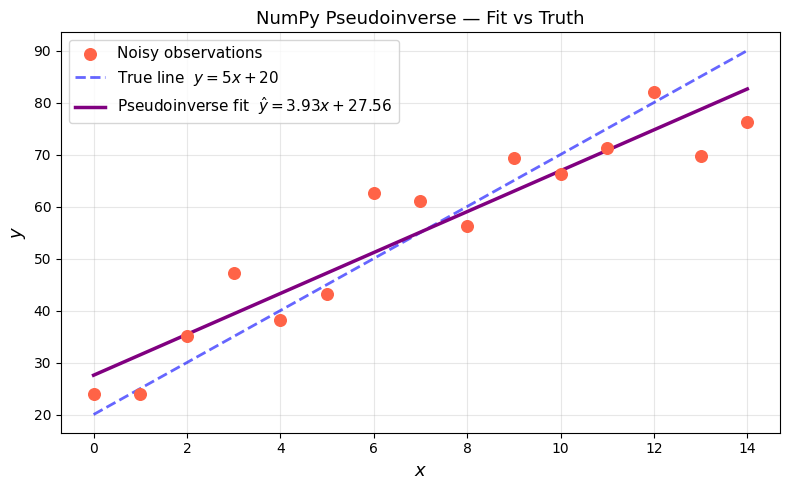

In [ ]:
# ── Predict & Plot ────────────────────────────────────────────────────────────
y_pred_np = X_np @ beta_np    # ŷ = Xβ̂

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color='tomato', s=70, zorder=5, label='Noisy observations')
ax.plot(x, y_clean,    'b--', linewidth=2, alpha=0.6, label='True line  $y=5x+20$')
ax.plot(x, y_pred_np,  'purple', linewidth=2.5,       label=f'Pseudoinverse fit  $\\hat{{y}}={w_np:.2f}x+{b_np:.2f}$')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$y$', fontsize=13)
ax.set_title('NumPy Pseudoinverse — Fit vs Truth', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Compare with sklearn:

In [ ]:
print(f"Difference: Δb = {abs(b_np - b_hat):.2e},  Δw = {abs(w_np - w_hat):.2e}   (numerical noise only)")

---
<a id='section7'></a>

# 7 · Evaluating the Model

How do we measure how good our fit is?  Two standard metrics:

### Mean Squared Error (MSE)

$$\text{MSE} = \frac{1}{N}\sum_{i=1}^N (y_i - \hat{y}_i)^2$$

- Measures **average squared residual**
- Same units² as $y$ → lower is better
- Sensitive to outliers (because of the square)

### Coefficient of Determination ($R^2$)

$$R^2 = 1 - \frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}$$

- Ranges from $-\infty$ to $1$
- $R^2 = 1$ → **perfect fit**
- $R^2 = 0$ → model is no better than predicting the mean
- $R^2 < 0$ → model is *worse* than predicting the mean

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y, y_pred)
r2  = r2_score(y, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score:                 {r2:.4f}")
print()
print("Interpretation:")
print(f"  → Our model explains {r2*100:.1f}% of the variance in y.")
print(f"  → Average squared error per point: {mse:.2f}")

Mean Squared Error (MSE): 37.7589
R² Score:                 0.8843

Interpretation:
  → Our model explains 88.4% of the variance in y.
  → Average squared error per point: 37.76


---
<a id='section_gd'></a>

# 6 · Fitting with Gradient Descent

**Gradient Descent** is an iterative alternative. Instead of solving directly, we start with a random guess for $w$ and $b$, then repeatedly nudge them in the direction that reduces the error.

---

## 6.1 · The Loss Function

We minimise the **Mean Squared Error (MSE)** over all $N$ training points:

$$\mathcal{L}(w, b) = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2 = \frac{1}{N} \sum_{i=1}^{N} (y_i - wx_i - b)^2$$

This is a smooth, convex bowl — it has exactly one global minimum, so gradient descent is guaranteed to find it.

---

## 6.2 · The Gradients

To know which direction to move $w$ and $b$, we compute the partial derivatives of $\mathcal{L}$:

$$\frac{\partial \mathcal{L}}{\partial w} = -\frac{2}{N} \sum_{i=1}^{N} x_i (y_i - \hat{y}_i)$$

$$\frac{\partial \mathcal{L}}{\partial b} = -\frac{2}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)$$

A positive gradient means the loss *increases* in that direction — so we step in the **opposite** direction.

---

## 6.3 · The Update Rule

At each iteration we subtract a small fraction of the gradient, controlled by the **learning rate** $\alpha$:

$$w \leftarrow w - \alpha \cdot \frac{\partial \mathcal{L}}{\partial w}$$

$$b \leftarrow b - \alpha \cdot \frac{\partial \mathcal{L}}{\partial b}$$



> **Too large $\alpha$** → overshoots the minimum, loss diverges.  
> **Too small $\alpha$** → converges correctly but very slowly.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ── Hyperparameters ───────────────────────────────────────────────────────────
learning_rate = 0.01
n_iterations  = 1000

# ── Initialise parameters at zero ────────────────────────────────────────────
w = 0.0
b = 0.0
N = len(x)

loss_history = []

# ── Gradient Descent Loop ─────────────────────────────────────────────────────
for i in range(n_iterations):

    # Forward pass — compute predictions with current w, b
    y_hat = w * x + b

    # Compute residuals
    residuals = y - y_hat

    # Compute loss (MSE)
    loss = np.mean(residuals ** 2)
    loss_history.append(loss)

    # Compute gradients
    dw = -2 * np.mean(x * residuals)
    db = -2 * np.mean(residuals)

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

print(f"True parameters:      w = {TRUE_SLOPE},       b = {TRUE_BIAS}")
print(f"Gradient Descent:     w = {w:.4f},  b = {b:.4f}")
print(f"sklearn (pseudoinv):  w = {w_hat:.4f},  b = {b_hat:.4f}")

True parameters:      w = 5,       b = 20
Gradient Descent:     w = 3.9440,  b = 27.4437
sklearn (pseudoinv):  w = 3.9323,  b = 27.5564


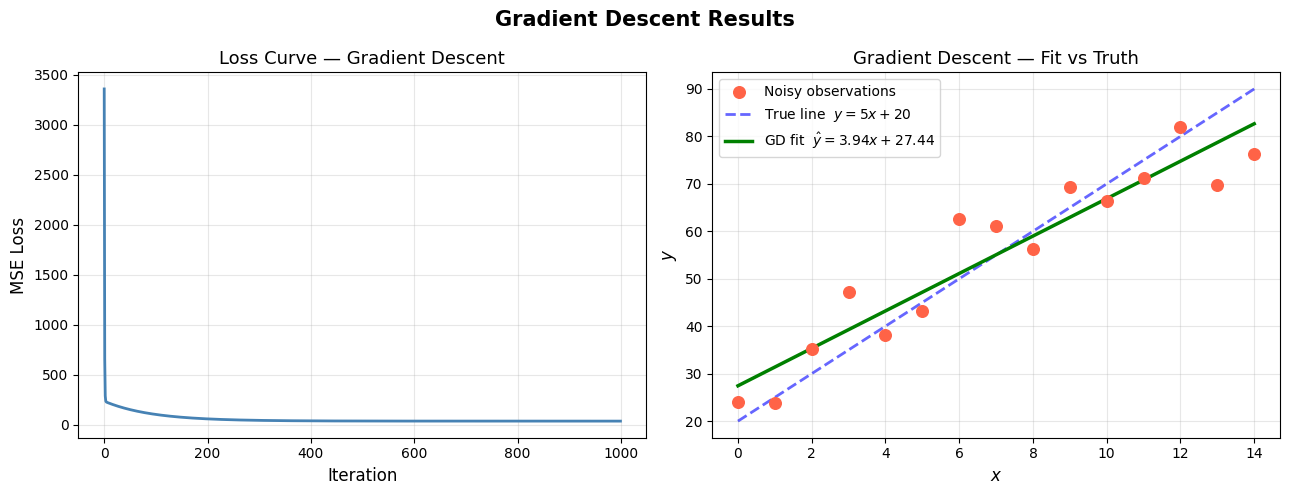

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: loss curve
axes[0].plot(loss_history, color='steelblue', linewidth=2)
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('MSE Loss', fontsize=12)
axes[0].set_title('Loss Curve — Gradient Descent', fontsize=13)
axes[0].grid(True, alpha=0.3)

# Right: fitted line vs data
y_pred_gd = w * x + b
axes[1].scatter(x, y, color='tomato', s=70, zorder=5, label='Noisy observations')
axes[1].plot(x, y_clean, 'b--', linewidth=2, alpha=0.6, label='True line  $y=5x+20$')
axes[1].plot(x, y_pred_gd, 'green', linewidth=2.5,
             label=f'GD fit  $\\hat{{y}}={w:.2f}x+{b:.2f}$')
axes[1].set_xlabel('$x$', fontsize=12)
axes[1].set_ylabel('$y$', fontsize=12)
axes[1].set_title('Gradient Descent — Fit vs Truth', fontsize=13)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Gradient Descent Results', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 6.4 · Evaluating Gradient Descent — Comparison with Previous Approaches

Now that we have learned $w$ and $b$ via gradient descent, we compute the same MSE and $R^2$ metrics as before and compare all three approaches side by side.

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

# ── Predictions from each approach ───────────────────────────────────────────
y_pred_gd    = w * x + b                  # gradient descent
# y_pred      is already defined — sklearn
# y_pred_np   is already defined — pseudoinverse

# ── Metrics ───────────────────────────────────────────────────────────────────
mse_gd    = mean_squared_error(y, y_pred_gd)
r2_gd     = r2_score(y, y_pred_gd)

mse_sk    = mean_squared_error(y, y_pred)
r2_sk     = r2_score(y, y_pred)

mse_pinv  = mean_squared_error(y, y_pred_np)
r2_pinv   = r2_score(y, y_pred_np)

# ── Summary table ─────────────────────────────────────────────────────────────
print("=" * 60)
print(f"{'Approach':<25} {'MSE':>10} {'R²':>10}")
print("=" * 60)
print(f"{'Gradient Descent':<25} {mse_gd:>10.4f} {r2_gd:>10.4f}")
print(f"{'sklearn (pinv)':<25} {mse_sk:>10.4f} {r2_sk:>10.4f}")
print(f"{'NumPy Pseudoinverse':<25} {mse_pinv:>10.4f} {r2_pinv:>10.4f}")
print("=" * 60)


Approach                         MSE         R²
Gradient Descent             37.7624     0.8843
sklearn (pinv)               37.7589     0.8843
NumPy Pseudoinverse          37.7589     0.8843


# -- Extra (Animation)--

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# ── Run gradient descent and save history ─────────────────────────────────────
learning_rate = 0.01
n_iterations  = 200
N             = len(x)

w_anim, b_anim = 0.0, 0.0
w_history      = [w_anim]
b_history      = [b_anim]
loss_history   = []

for i in range(n_iterations):
    y_hat     = w_anim * x + b_anim
    residuals = y - y_hat
    loss      = np.mean(residuals ** 2)
    loss_history.append(loss)

    dw = (-2 / N) * np.sum(x * residuals)
    db = (-2 / N) * np.sum(residuals)

    w_anim -= learning_rate * dw
    b_anim -= learning_rate * db

    w_history.append(w_anim)
    b_history.append(b_anim)

# ── Set up figure ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plt.suptitle('Gradient Descent — Live Training', fontsize=14, fontweight='bold')

# Left ax — fitted line
ax1 = axes[0]
ax1.scatter(x, y, color='tomato', s=60, zorder=5, label='Data')
ax1.plot(x, y_clean, 'b--', linewidth=1.5, alpha=0.5, label='True line $y=5x+20$')
fitted_line, = ax1.plot([], [], 'green', linewidth=2.5, label='GD fit')
epoch_text   = ax1.text(0.05, 0.92, '', transform=ax1.transAxes, fontsize=11,
                         bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
param_text   = ax1.text(0.05, 0.80, '', transform=ax1.transAxes, fontsize=10,
                         bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
ax1.set_xlim(-0.5, 14.5)
ax1.set_ylim(min(y) - 10, max(y) + 10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_title('Fitted Line per Epoch', fontsize=12)
ax1.legend(fontsize=10, loc='lower right')
ax1.grid(True, alpha=0.3)

# Right ax — loss curve
ax2 = axes[1]
ax2.set_xlim(0, n_iterations)
ax2.set_ylim(0, max(loss_history) * 1.1)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('MSE Loss', fontsize=12)
ax2.set_title('Loss Curve', fontsize=12)
ax2.grid(True, alpha=0.3)
loss_line, = ax2.plot([], [], color='steelblue', linewidth=2)
loss_dot,  = ax2.plot([], [], 'o', color='steelblue', markersize=6)

plt.tight_layout()

# ── Animation update function ─────────────────────────────────────────────────
def update(frame):
    w_f = w_history[frame]
    b_f = b_history[frame]

    # Update fitted line
    y_fit = w_f * x + b_f
    fitted_line.set_data(x, y_fit)

    # Update text
    epoch_text.set_text(f'Epoch {frame}')
    param_text.set_text(f'w = {w_f:.3f}\nb = {b_f:.3f}')

    # Update loss curve
    epochs_so_far = list(range(frame))
    loss_line.set_data(epochs_so_far, loss_history[:frame])
    if frame > 0:
        loss_dot.set_data([frame - 1], [loss_history[frame - 1]])

    return fitted_line, epoch_text, param_text, loss_line, loss_dot

# ── Build and display animation ───────────────────────────────────────────────
anim = FuncAnimation(
    fig,
    update,
    frames=n_iterations + 1,
    interval=50,          # milliseconds between frames
    blit=True
)

plt.close()               # prevents a static duplicate from showing
HTML(anim.to_jshtml())    # renders interactively in Colab

Output hidden; open in https://colab.research.google.com to view.